# EDA 03 · Priors por categoría y stock en el tiempo

1. **Prior de compra por categoría:** P(categoría) = compras en la categoría / compras totales, con todos los usuarios juntos. Se calcula con el histórico (`shop.history_events`, 60 días) y se compara con el stream en vivo (`shop.events`).
2. **Prior de subcategoría dentro de su categoría:** P(subcategoría | categoría).
3. **Estabilidad semanal** de P(categoría) en el histórico.
4. **Stock en el tiempo:** % de productos en stock por categoría, reconstruido con `shop.catalog_updates`. El histórico no tiene stock: solo hay datos desde que abrió el stream (sáb 09:00 UTC).

Las horas están en UTC (CET = UTC+1).

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

for p in [Path(".env"), Path("../.env"), Path("../datathon-fme-2026/.env")]:
    if p.exists():
        for line in p.read_text().splitlines():
            k, _, v = line.partition("=")
            if k.strip():
                os.environ.setdefault(k.strip(), v.strip())
        break
API = os.environ.get("RAWTREE_API_URL", "https://api.rawtree.com")
http = requests.Session()
http.headers["Authorization"] = f"Bearer {os.environ['RAWTREE_API_KEY']}"

def sql(q):
    r = http.post(f"{API}/v1/query", json={"sql": q}, timeout=900)
    r.raise_for_status()
    return pd.DataFrame(r.json()["data"])

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#e8762c", "#1f2328", "#6b7280", "#e5e7eb"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True})
FIG = Path("fig"); FIG.mkdir(exist_ok=True)
CAT = "(SELECT product_id::String AS p, category::String AS cat, subcategory::String AS sub FROM shop.catalog)"

## 1. P(categoría): histórico frente a stream en vivo

In [2]:
hist = sql(f"""SELECT c.cat AS category, c.sub AS subcategory, count() AS compras
FROM (SELECT product_id::String AS p FROM shop.history_events WHERE event_type::String = 'purchase') AS e
INNER JOIN {CAT} AS c ON c.p = e.p GROUP BY category, subcategory""")
live = sql(f"""SELECT c.cat AS category, count() AS compras
FROM (SELECT product_id::String AS p FROM shop.events WHERE event_type::String = 'purchase') AS e
INNER JOIN {CAT} AS c ON c.p = e.p GROUP BY category""")
cat_n = sql("SELECT category::String AS category, count() AS productos FROM shop.catalog GROUP BY category")

pr = (hist.groupby("category").compras.sum().rename("compras_hist").to_frame()
      .join(live.set_index("category").compras.rename("compras_vivo"))
      .join(cat_n.set_index("category").productos))
pr["P_hist"] = pr.compras_hist / pr.compras_hist.sum()
pr["P_vivo"] = pr.compras_vivo / pr.compras_vivo.sum()
pr["cuota_catalogo"] = pr.productos / pr.productos.sum()
pr["indice_demanda"] = pr.P_hist / pr.cuota_catalogo          # >1: vende más de lo que pesa en el catálogo
pr = pr.sort_values("P_hist", ascending=False)
print(f"compras histórico: {pr.compras_hist.sum():,} · compras en vivo (sólo productos del catálogo inicial): {int(pr.compras_vivo.sum()):,}".replace(",", "."))
pr[["productos", "compras_hist", "P_hist", "P_vivo", "cuota_catalogo", "indice_demanda"]].round(3)

compras histórico: 548.160 · compras en vivo (sólo productos del catálogo inicial): 74.613


,productos,compras_hist,P_hist,P_vivo,cuota_catalogo,indice_demanda
category,,,,,,
Books & Media,553,133565,0.244,0.237,0.111,2.203
Toys & Baby,516,76682,0.140,0.135,0.103,1.356
Electronics,580,60078,0.110,0.106,0.116,0.945
Sports & Outdoors,489,57663,0.105,0.106,0.098,1.076
Fashion,394,55121,0.101,0.096,0.079,1.276
Computers & Gaming,427,50553,0.092,0.093,0.085,1.080
Beauty & Health,322,36899,0.067,0.064,0.064,1.045
Pets,613,29696,0.054,0.062,0.123,0.442
Home & Kitchen,466,28969,0.053,0.062,0.093,0.567


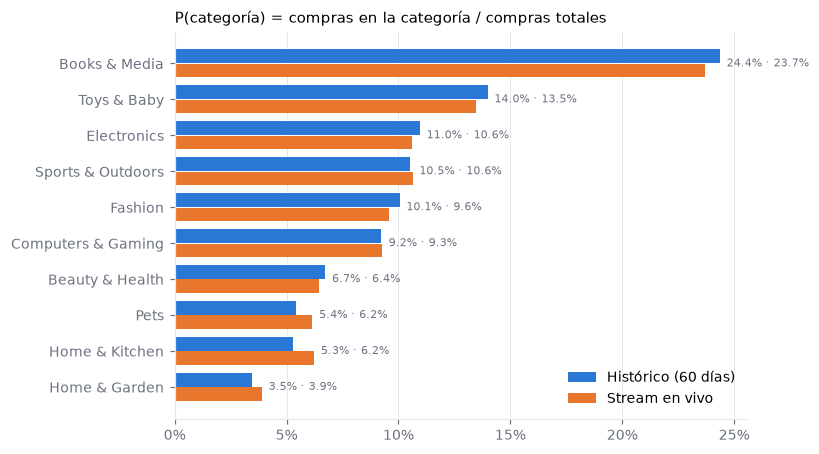

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
y = np.arange(len(pr))
ax.barh(y - 0.2, pr.P_hist, height=0.38, color=BLUE, label="Histórico (60 días)")
ax.barh(y + 0.2, pr.P_vivo, height=0.38, color=ORANGE, label="Stream en vivo")
for i, (a, b) in enumerate(zip(pr.P_hist, pr.P_vivo)):
    ax.text(max(a, b) + 0.003, i, f"{a:.1%} · {b:.1%}", va="center", fontsize=7.5, color=MUTED)
ax.set_yticks(y, pr.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_title("P(categoría) = compras en la categoría / compras totales", loc="left", fontsize=10)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "prior_categoria.png", bbox_inches="tight"); plt.show()

## 2. P(subcategoría | categoría)

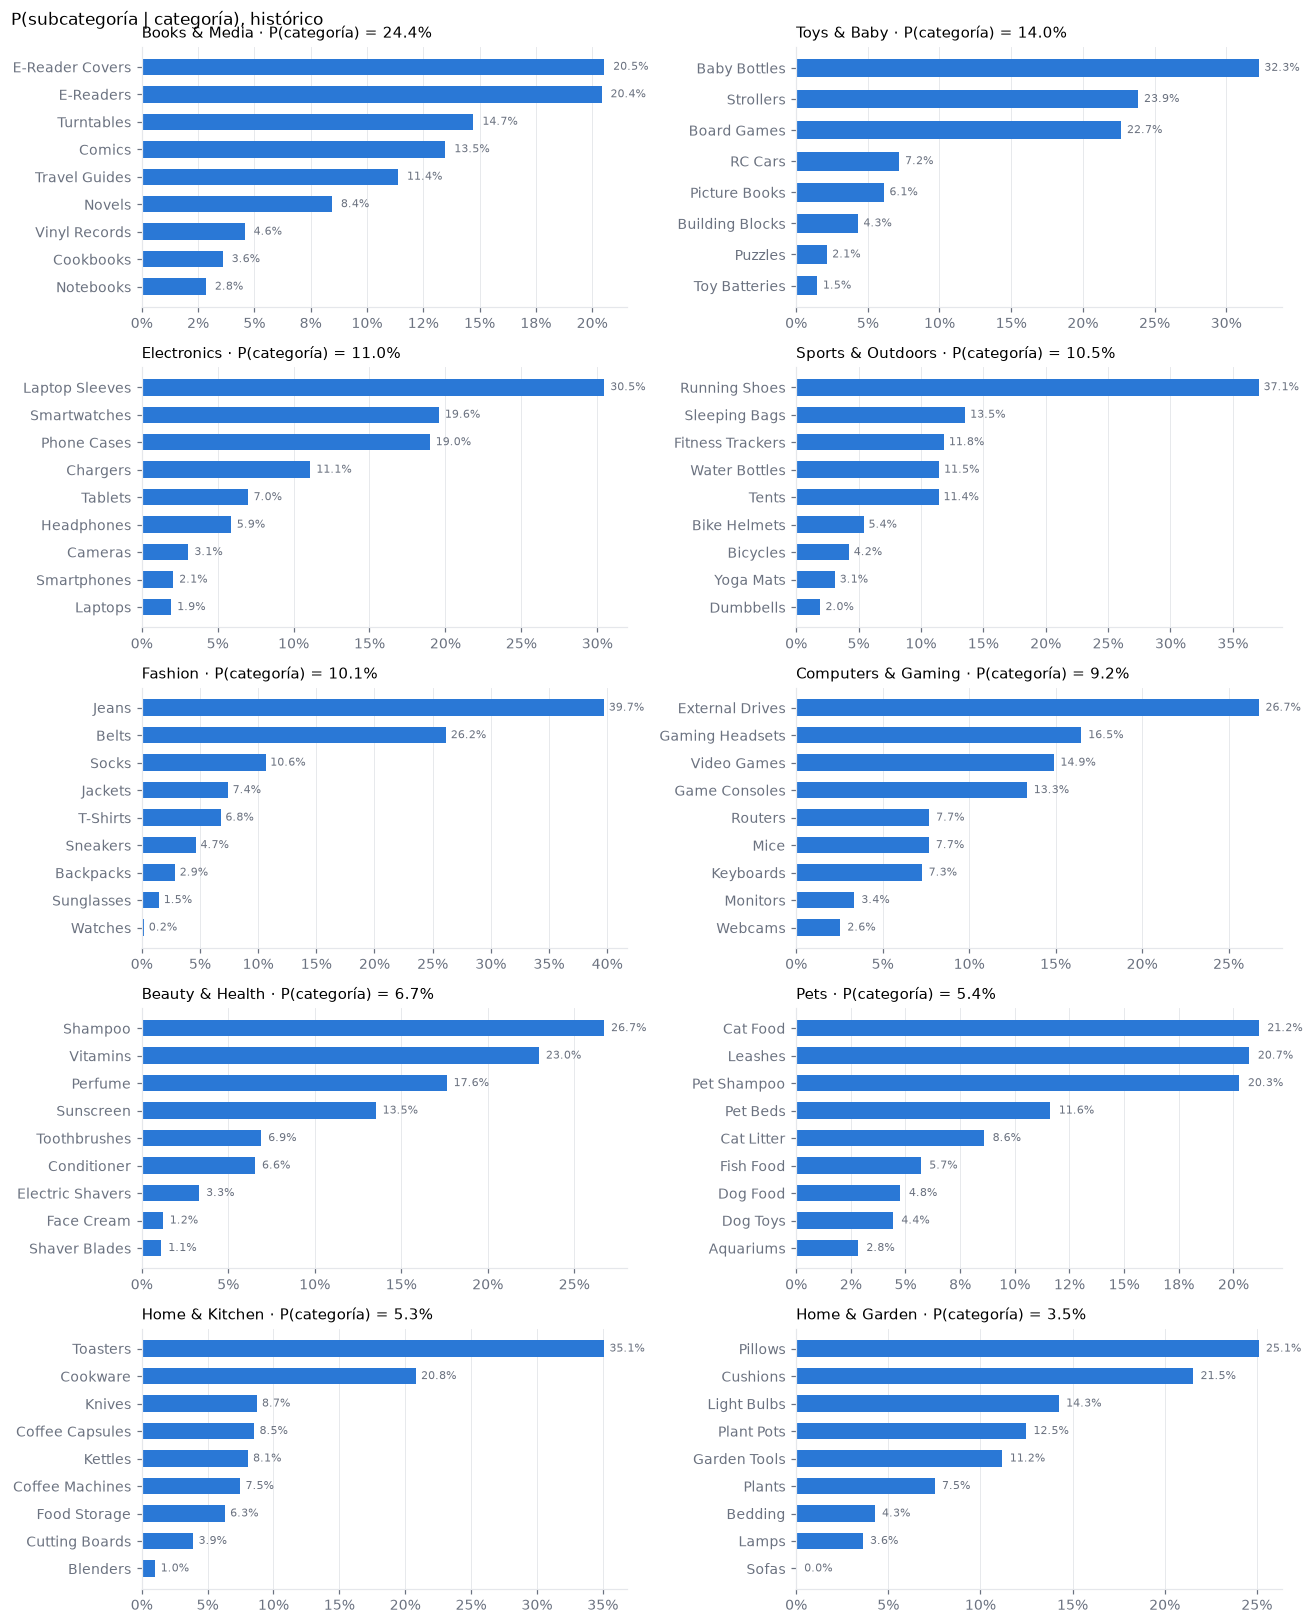

In [4]:
hist["P_sub_dado_cat"] = hist.compras / hist.groupby("category").compras.transform("sum")
fig, axes = plt.subplots(5, 2, figsize=(12, 15))
for ax, cat in zip(axes.flat, pr.index):
    s = hist[hist.category == cat].sort_values("P_sub_dado_cat", ascending=False)
    ax.barh(s.subcategory, s.P_sub_dado_cat, color=BLUE, height=0.6)
    for i, v in enumerate(s.P_sub_dado_cat):
        ax.text(v + 0.004, i, f"{v:.1%}", va="center", fontsize=7.5, color=MUTED)
    ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(f"{cat} · P(categoría) = {pr.loc[cat, 'P_hist']:.1%}", loc="left", fontsize=9.5)
plt.suptitle("P(subcategoría | categoría), histórico", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "prior_subcategoria.png", bbox_inches="tight"); plt.show()

## 3. ¿Es estable P(categoría) semana a semana?

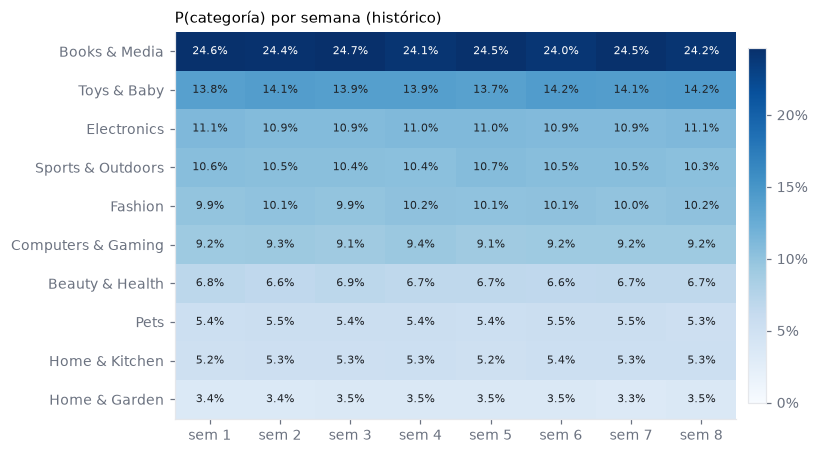

desviación típica entre semanas (puntos porcentuales):
category
Books & Media         0.24
Toys & Baby           0.19
Electronics           0.11
Sports & Outdoors     0.13
Fashion               0.12
Computers & Gaming    0.11
Beauty & Health       0.11
Pets                  0.08
Home & Kitchen        0.06
Home & Garden         0.08


In [5]:
wk = sql(f"""SELECT c.cat AS category, intDiv(dateDiff('day', toDateTime64('2026-09-15 07:00:00', 3), e.t), 7) AS semana,
  count() AS compras
FROM (SELECT product_id::String AS p, ts::DateTime64(3) AS t FROM shop.history_events WHERE event_type::String = 'purchase') AS e
INNER JOIN {CAT} AS c ON c.p = e.p GROUP BY category, semana""")
wk = wk[wk.semana < 8]
W = wk.pivot_table(index="category", columns="semana", values="compras", aggfunc="sum")
W = (W / W.sum()).loc[pr.index]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
im = ax.imshow(W.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(W.shape[1]), [f"sem {c + 1}" for c in W.columns]); ax.set_yticks(range(len(W)), W.index)
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        ax.text(j, i, f"{W.values[i, j]:.1%}", ha="center", va="center", fontsize=7.5,
                color="white" if W.values[i, j] > 0.6 * W.values.max() else INK)
ax.grid(False)
ax.set_title("P(categoría) por semana (histórico)", loc="left", fontsize=10)
plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02, format=PercentFormatter(1.0, decimals=0))
plt.tight_layout(); plt.savefig(FIG / "prior_categoria_semanas.png", bbox_inches="tight"); plt.show()
print("desviación típica entre semanas (puntos porcentuales):")
print((100 * W.std(axis=1)).round(2).to_string())

## 4. Proporción de productos en stock a lo largo del tiempo

Se parte del catálogo inicial (5.000 productos, todos activos) y se aplican en orden los `catalog_updates`: `new_product` añade un producto, `out_of_stock` lo quita del stock y `back_in_stock` lo devuelve. Se evalúa cada 5 minutos.

In [6]:
cat0 = sql("SELECT product_id::String AS p, category::String AS category FROM shop.catalog")
upd = sql("""SELECT product_id::String AS p, ts::DateTime64(3) AS ts, change::String AS change, category::String AS category
FROM shop.catalog_updates ORDER BY ts, p""")
upd["ts"] = pd.to_datetime(upd.ts)
print(upd.change.value_counts().to_string())
cat_of = dict(zip(cat0.p, cat0.category))
in_stock = {p: True for p in cat0.p}
grid = pd.date_range(upd.ts.min().floor("5min"), pd.Timestamp.now("UTC").tz_localize(None).floor("5min"), freq="5min")
rows, k = [], 0
ev = upd.sort_values("ts").to_dict("records")
for t in grid:
    while k < len(ev) and ev[k]["ts"] <= t:
        e = ev[k]; k += 1
        if e["change"] == "new_product":
            cat_of.setdefault(e["p"], e["category"]); in_stock.setdefault(e["p"], True)
        elif e["change"] == "out_of_stock":
            in_stock[e["p"]] = False
        elif e["change"] == "back_in_stock":
            in_stock[e["p"]] = True
    s = pd.Series(in_stock)
    g = pd.DataFrame({"category": [cat_of[p] for p in s.index], "stock": s.values}).groupby("category").stock
    rows.append(pd.DataFrame({"t": t, "productos": g.size(), "en_stock": g.sum()}))
st = pd.concat(rows).reset_index(names="category")
st["pct_stock"] = st.en_stock / st.productos
st["sin_stock"] = st.productos - st.en_stock
st.groupby("category").pct_stock.agg(["min", "mean", "last"]).round(4)

change
price_change     2560
out_of_stock      255
back_in_stock     219
new_product       200


,min,mean,last
category,,,
Beauty & Health,0.9818,0.9921,0.9881
Books & Media,0.9740,0.9843,0.9827
Computers & Gaming,0.9840,0.9927,0.9955
Electronics,0.9915,0.9944,0.9967
Fashion,0.9803,0.9903,0.9903
Home & Garden,0.9954,0.9978,0.9985
Home & Kitchen,0.9895,0.9959,0.9939
Pets,0.9968,0.9986,1.0000
Sports & Outdoors,0.9859,0.9922,0.9940


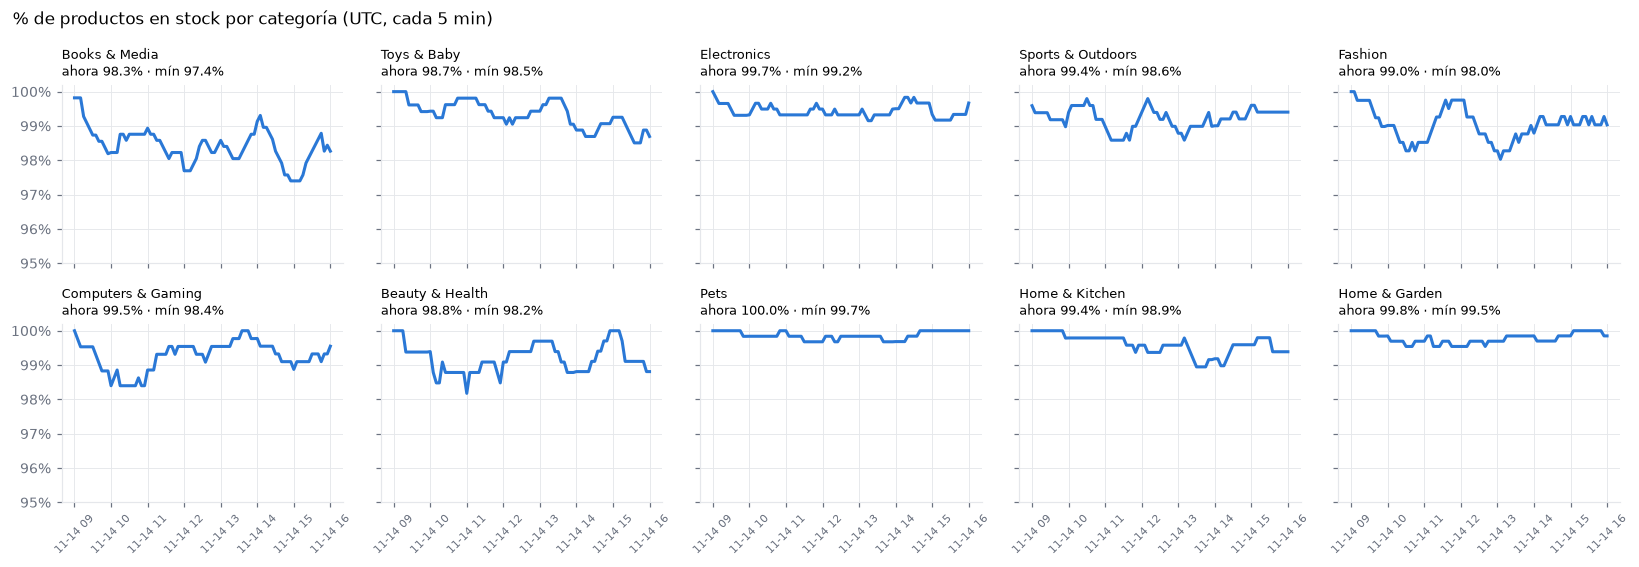

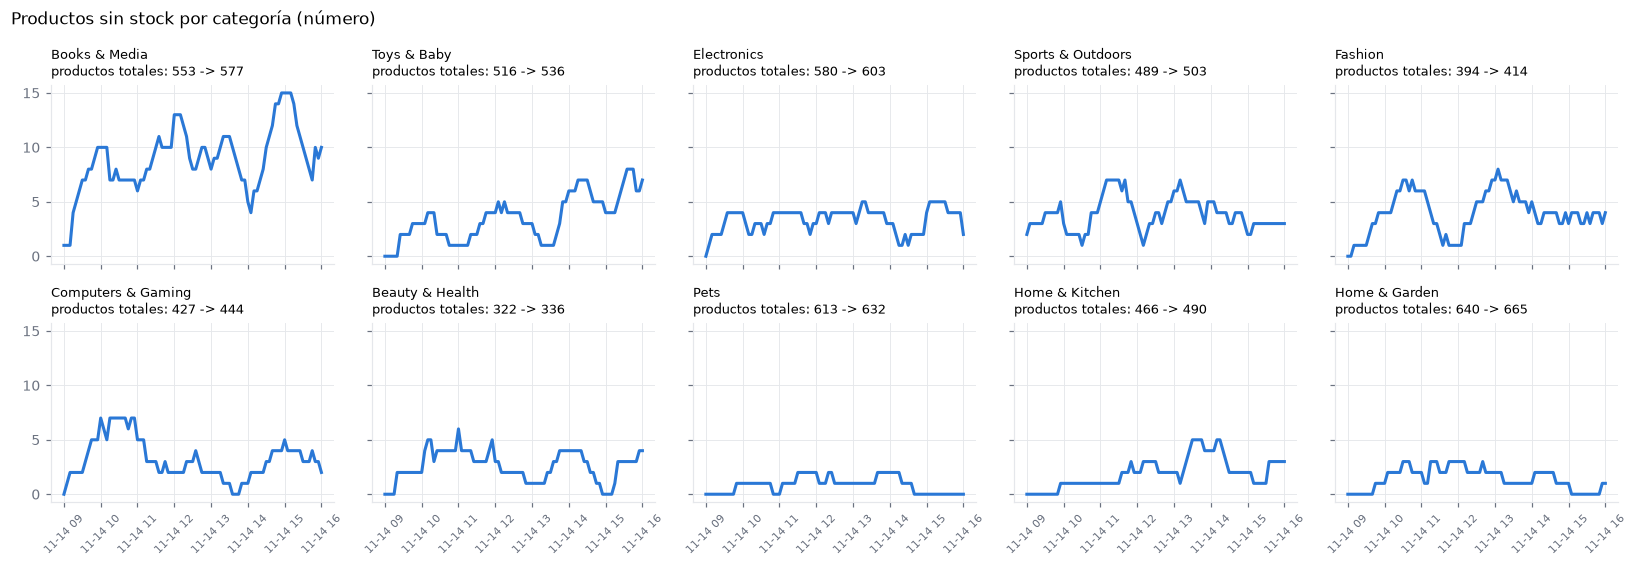

In [7]:
order = pr.index.tolist()
fig, axes = plt.subplots(2, 5, figsize=(15, 5.2), sharey=True, sharex=True)
lo = min(0.95, st.pct_stock.min() - 0.005)
for ax, cat in zip(axes.flat, order):
    s = st[st.category == cat]
    ax.plot(s.t, s.pct_stock, color=BLUE, lw=2)
    ax.set_title(f"{cat}\nahora {s.pct_stock.iloc[-1]:.1%} · mín {s.pct_stock.min():.1%}", loc="left", fontsize=8.5)
    ax.set_ylim(lo, 1.002)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
plt.suptitle("% de productos en stock por categoría (UTC, cada 5 min)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "stock_categoria.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(2, 5, figsize=(15, 5.2), sharey=True, sharex=True)
for ax, cat in zip(axes.flat, order):
    s = st[st.category == cat]
    ax.plot(s.t, s.sin_stock, color=BLUE, lw=2)
    ax.set_title(f"{cat}\nproductos totales: {int(s.productos.iloc[0])} -> {int(s.productos.iloc[-1])}", loc="left", fontsize=8.5)
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
plt.suptitle("Productos sin stock por categoría (número)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "sin_stock_categoria.png", bbox_inches="tight"); plt.show()